# Reflexión y transmisión de una onda electromagnética en una interfaz

## 1. Enunciado

Una onda electromagnética plana y monocromática se propaga en la dirección
positiva del eje z dentro de un medio de índice de refracción n₁.
En z = 0 encuentra una interfaz plana con un segundo medio de índice n₂.

Ambos medios son lineales, homogéneos, no conductores y no absorben energía.
Se supone que sus permeabilidades son iguales a la del vacío y que sus
índices de refracción son constantes en el intervalo de frecuencias estudiado.

El objetivo es visualizar simultáneamente las ondas incidente, reflejada
y transmitida, mostrando la evolución temporal de sus campos eléctricos.

El programa permitirá:

- Modificar los índices de refracción de ambos medios.
- Observar el cambio de fase de la onda reflejada.
- Examinar la continuidad de los campos en la interfaz.
- Calcular el vector de Poynting promedio de cada onda.
- Determinar las fracciones de potencia reflejada y transmitida.
- Comprobar numéricamente la conservación de la energía.

Se utilizan soluciones analíticas. El programa evalúa estas expresiones
para dibujar los campos; no resuelve numéricamente las ecuaciones de Maxwell.

El problema corresponde al ejemplo 3.2 del proyecto y se relaciona con
la sección 9.3 de Griffiths.

In [1]:
%pip install -q numpy matplotlib ipywidgets

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

C = 299_792_458.0
Z0 = 376.730313668

Note: you may need to restart the kernel to use updated packages.


## 2. Modelo analítico

El campo eléctrico está orientado en la dirección x.
El campo magnético está orientado en la dirección y.

La frecuencia angular y los números de onda son:

$$
\omega = 2\pi f,
\qquad
k_1 = \frac{n_1\omega}{c},
\qquad
k_2 = \frac{n_2\omega}{c}.
$$

Para z < 0, los campos eléctricos incidente y reflejado son:

$$
E_i(z,t)=E_0\cos(k_1z-\omega t),
$$

$$
E_r(z,t)=rE_0\cos(k_1z+\omega t).
$$

Para z > 0, el campo transmitido es:

$$
E_t(z,t)=t_EE_0\cos(k_2z-\omega t).
$$

El signo de la dependencia temporal permite distinguir las direcciones:
la onda incidente y la transmitida viajan hacia +z; la reflejada viaja hacia -z.

### Condiciones de frontera

En ausencia de corrientes superficiales libres, los campos tangenciales
E y H son continuos:

$$
E_i(0,t)+E_r(0,t)=E_t(0,t),
$$

$$
H_i(0,t)+H_r(0,t)=H_t(0,t).
$$

Las relaciones entre los campos son:

$$
H_i=\frac{n_1}{Z_0}E_i,
\qquad
H_r=-\frac{n_1}{Z_0}E_r,
\qquad
H_t=\frac{n_2}{Z_0}E_t.
$$

El signo negativo de H_r aparece porque la onda reflejada viaja hacia -z.

Las condiciones de frontera dan:

$$
1+r=t_E,
\qquad
n_1(1-r)=n_2t_E.
$$

Al resolver estas dos ecuaciones:

$$
r=\frac{n_1-n_2}{n_1+n_2},
\qquad
t_E=\frac{2n_1}{n_1+n_2}.
$$

### Transporte de energía

El vector de Poynting es:

$$
\mathbf{S}=\mathbf{E}\times\mathbf{H}.
$$

Sus componentes longitudinales, promediadas durante un período, son:

$$
\langle S_{i,z}\rangle=\frac{n_1E_0^2}{2Z_0},
$$

$$
\langle S_{r,z}\rangle=-\frac{n_1r^2E_0^2}{2Z_0},
$$

$$
\langle S_{t,z}\rangle=\frac{n_2t_E^2E_0^2}{2Z_0}.
$$

El signo negativo del flujo reflejado indica su dirección.

Las fracciones de potencia reflejada y transmitida se definen como:

$$
R=\frac{|\langle S_{r,z}\rangle|}{\langle S_{i,z}\rangle}=r^2,
$$

$$
T=\frac{\langle S_{t,z}\rangle}{\langle S_{i,z}\rangle}
=\frac{n_2}{n_1}t_E^2.
$$

Para medios sin absorción:

$$
R+T=
\frac{(n_1-n_2)^2+4n_1n_2}{(n_1+n_2)^2}
=1.
$$

In [ ]:
def coeficientes(n1, n2):
    if n1 <= 0 or n2 <= 0:
        raise ValueError("Los índices deben ser positivos.")

    r = (n1 - n2) / (n1 + n2)
    tE = 2 * n1 / (n1 + n2)
    R = r**2
    T = (n2 / n1) * tE**2
    return r, tE, R, T


def campos(z, tiempo, n1, n2, E0=1.0, f=100e6):
    z = np.asarray(z)
    r, tE, _, _ = coeficientes(n1, n2)
    omega = 2 * np.pi * f
    k1 = n1 * omega / C
    k2 = n2 * omega / C
    Ei = E0 * np.cos(k1 * z - omega * tiempo)
    Er = r * E0 * np.cos(k1 * z + omega * tiempo)
    Et = tE * E0 * np.cos(k2 * z - omega * tiempo)
    return Ei, Er, Et


def poynting(n1, n2, E0=1.0):
    r, tE, _, _ = coeficientes(n1, n2)
    Si = n1 * E0**2 / (2 * Z0)
    Sr = -n1 * (r * E0)**2 / (2 * Z0)
    St = n2 * (tE * E0)**2 / (2 * Z0)
    return Si, Sr, St


def frontera(tiempo, n1, n2, E0=1.0, f=100e6):
    Ei, Er, Et = campos(0.0, tiempo, n1, n2, E0, f)
    E_izq = Ei + Er
    E_der = Et
    H_izq = n1 * (Ei - Er) / Z0
    H_der = n2 * Et / Z0
    return E_izq, E_der, H_izq, H_der

## 3. Comprobación de la energía y de las condiciones de frontera

Se comparan tres casos:

1. n₂ > n₁.
2. n₂ < n₁.
3. n₂ = n₁.

Además, se evalúan distintas combinaciones de índices e instantes
para comprobar la continuidad de E y H y la conservación de la potencia.

Como el flujo reflejado tiene signo negativo, el balance se escribe:

$$
\langle S_{i,z}\rangle+\langle S_{r,z}\rangle
=\langle S_{t,z}\rangle.
$$

El error relativo utilizado es:

$$
\varepsilon_S=
\frac{|\langle S_{i,z}\rangle+\langle S_{r,z}\rangle
-\langle S_{t,z}\rangle|}
{\langle S_{i,z}\rangle}.
$$

Los errores deben ser cercanos a cero. Pueden aparecer diferencias
muy pequeñas debido al redondeo de las operaciones del computador.

In [3]:
casos = [
    (1.0, 1.5),
    (1.5, 1.0),
    (1.5, 1.5),
]

print(" n1    n2       r      t_E       R        T      R+T")
print("-" * 62)

for n1, n2 in casos:
    r, tE, R, T = coeficientes(n1, n2)

    print(
        f"{n1:4.1f}  {n2:4.1f}  {r:7.3f}  {tE:7.3f}  "
        f"{R:7.3f}  {T:7.3f}  {R + T:7.3f}"
    )

error_energia_max = 0.0
error_E_max = 0.0
error_H_max = 0.0

f_prueba = 100e6

for n1 in np.linspace(1, 3, 41):
    for n2 in np.linspace(1, 3, 41):
        Si, Sr, St = poynting(n1, n2)

        error = abs(Si + Sr - St) / Si
        error_energia_max = max(error_energia_max, error)

        for tau in np.linspace(0, 1, 9):
            tiempo = tau / f_prueba

            E1, E2, H1, H2 = frontera(
                tiempo, n1, n2, f=f_prueba
            )

            error_E_max = max(error_E_max, abs(E1 - E2))
            error_H_max = max(error_H_max, abs(H1 - H2))

print("\nErrores máximos:")
print(f"Balance de potencia: {error_energia_max:.3e}")
print(f"Continuidad de E:    {error_E_max:.3e} V/m")
print(f"Continuidad de H:    {error_H_max:.3e} A/m")

assert error_energia_max < 1e-12
assert error_E_max < 1e-12
assert error_H_max < 1e-12

print("\nLas comprobaciones físicas se cumplen.")

 n1    n2       r      t_E       R        T      R+T
--------------------------------------------------------------
 1.0   1.5   -0.200    0.800    0.040    0.960    1.000
 1.5   1.0    0.200    1.200    0.040    0.960    1.000
 1.5   1.5    0.000    1.000    0.000    1.000    1.000

Errores máximos:
Balance de potencia: 5.446e-16
Continuidad de E:    2.220e-16 V/m
Continuidad de H:    1.735e-18 A/m

Las comprobaciones físicas se cumplen.


## 4. Visualización de los campos

La primera gráfica muestra las ondas incidente, reflejada y transmitida.
Cada onda se dibuja únicamente en el medio donde está presente.

La segunda gráfica muestra el campo eléctrico total:

$$
E_{\mathrm{total}}=
\begin{cases}
E_i+E_r, & z<0,\\
E_t, & z>0.
\end{cases}
$$

Ambas gráficas utilizan la misma escala vertical para permitir
comparar sus amplitudes.

La tercera gráfica muestra los porcentajes de potencia reflejada
y transmitida. Estos porcentajes corresponden a promedios temporales,
por lo que permanecen constantes mientras se animan los campos.

El tiempo se expresa mediante:

$$
\tau=ft=\frac{t}{P},
\qquad P=\frac{1}{f}.
$$

Así, τ = 1 representa un período completo.

In [4]:
def crear_figura(n1, n2, E0=1.0, f_MHz=100.0, tau=0.0):
    f = f_MHz * 1e6
    tiempo = tau / f

    r, tE, R, T = coeficientes(n1, n2)

    z1 = np.linspace(-8, 0, 700)
    z2 = np.linspace(0, 8, 700)

    Ei, Er, _ = campos(z1, tiempo, n1, n2, E0, f)
    _, _, Et = campos(z2, tiempo, n1, n2, E0, f)

    fig, axes = plt.subplots(
        3, 1,
        figsize=(10, 8),
        layout="constrained",
        gridspec_kw={"height_ratios": [2, 2, 1]}
    )

    limite = 1.15 * E0 * max(1 + abs(r), tE)

    for ax in axes[:2]:
        ax.axvspan(-8, 0, color="#2563eb", alpha=0.06)
        ax.axvspan(0, 8, color="#059669", alpha=0.06)

        ax.axvline(
            0, color="black", linestyle="--", label="Interfaz"
        )
        ax.axhline(0, color="gray", linewidth=0.7)

        ax.set(
            xlim=(-8, 8),
            ylim=(-limite, limite),
            xlabel="z (m)",
            ylabel="E (V/m)"
        )
        ax.grid(alpha=0.25)

    axes[0].plot(
        z1, Ei, color="#2563eb", label="Incidente → +z"
    )
    axes[0].plot(
        z1, Er, color="#c2410c", label="Reflejada → -z"
    )
    axes[0].plot(
        z2, Et, color="#059669", label="Transmitida → +z"
    )

    axes[0].set_title("Campos eléctricos de las tres ondas")
    axes[0].legend(loc="upper right", ncols=2, fontsize=8)

    axes[1].plot(
        z1, Ei + Er, color="#7c3aed", label="Eᵢ + Eᵣ"
    )
    axes[1].plot(
        z2, Et, color="#7c3aed", linestyle="--", label="Eₜ"
    )

    axes[1].set_title("Campo total: continuidad en z = 0")
    axes[1].legend(loc="upper right")

    axes[2].barh(
        ["Potencia"], [100 * R],
        color="#c2410c",
        label=f"Reflejada: {100 * R:.2f}%"
    )
    axes[2].barh(
        ["Potencia"], [100 * T],
        left=[100 * R],
        color="#059669",
        label=f"Transmitida: {100 * T:.2f}%"
    )

    axes[2].set(
        xlim=(0, 100),
        xlabel="Porcentaje de potencia incidente"
    )
    axes[2].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.42),
        ncols=2,
        fontsize=9
    )

    fig.suptitle(
        f"n₁ = {n1:.2f} | n₂ = {n2:.2f} | f = {f_MHz:.0f} MHz\n"
        f"t = {tiempo * 1e9:.2f} ns = {tau:.2f} períodos | "
        f"r = {r:.3f} | t_E = {tE:.3f}"
    )

    return fig

## 5. Exploración interactiva

Los controles permiten modificar los índices, la amplitud incidente
y la frecuencia.

El botón de reproducción muestra la evolución temporal.
Cada cuadro corresponde a un avance de P/40.
La animación está ralentizada para poder observar los campos.

Explore estas situaciones:

- n₁ = 1 y n₂ = 1.5: observe la inversión de fase reflejada.
- n₁ = 1.5 y n₂ = 1: compare la amplitud transmitida con la incidente.
- n₁ = n₂: compruebe que desaparece la reflexión.

Observe también que el campo total es continuo en la interfaz,
aunque las ondas individuales tengan diferentes amplitudes.

Al modificar un parámetro se representa otra solución monocromática.
No se calcula el transitorio físico producido por cambiar el material.

En este modelo sin dispersión, cambiar la frecuencia modifica las
longitudes de onda, pero no los coeficientes R y T.

In [5]:
def actualizar(n1, n2, E0, f_MHz, cuadro):
    tau = cuadro / 40
    f = f_MHz * 1e6
    tiempo = tau / f

    fig = crear_figura(n1, n2, E0, f_MHz, tau)
    display(fig)
    plt.close(fig)

    Si, Sr, St = poynting(n1, n2, E0)
    E1, E2, H1, H2 = frontera(tiempo, n1, n2, E0, f)

    print("Poynting promedio: componente en z")
    print(f"Incidente:   {Si:.6e} W/m²")
    print(f"Reflejada:   {Sr:.6e} W/m²")
    print(f"Transmitida: {St:.6e} W/m²")

    print("\nCampos en la interfaz:")
    print(f"E lado 1 = {E1:.6f} | E lado 2 = {E2:.6f} V/m")
    print(f"H lado 1 = {H1:.8f} | H lado 2 = {H2:.8f} A/m")

    print(f"\nError relativo de potencia: {abs(Si + Sr - St) / Si:.3e}")


n1_control = widgets.FloatSlider(
    value=1.0, min=1.0, max=3.0, step=0.05,
    description="n₁:", continuous_update=False
)

n2_control = widgets.FloatSlider(
    value=1.5, min=1.0, max=3.0, step=0.05,
    description="n₂:", continuous_update=False
)

E0_control = widgets.FloatSlider(
    value=1.0, min=0.2, max=5.0, step=0.1,
    description="E₀ (V/m):", continuous_update=False
)

f_control = widgets.FloatSlider(
    value=100, min=50, max=200, step=5,
    description="f (MHz):", continuous_update=False
)

cuadro_control = widgets.IntSlider(
    value=0, min=0, max=80, step=1,
    description="Cuadro:", continuous_update=False
)

reproductor = widgets.Play(
    value=0, min=0, max=80, step=1,
    interval=250
)

enlace_tiempo = widgets.jslink(
    (reproductor, "value"),
    (cuadro_control, "value")
)

salida = widgets.interactive_output(
    actualizar,
    {
        "n1": n1_control,
        "n2": n2_control,
        "E0": E0_control,
        "f_MHz": f_control,
        "cuadro": cuadro_control,
    }
)

panel = widgets.VBox([
    widgets.HBox([n1_control, n2_control]),
    widgets.HBox([E0_control, f_control]),
    widgets.HBox([reproductor, cuadro_control]),
])

display(panel, salida)

Output()

## 6. Comparación de casos

Las siguientes gráficas muestran tres situaciones en el mismo
instante relativo, τ = 0.125.

Estas figuras quedan guardadas como salidas del notebook y permiten
examinar los resultados sin utilizar los controles interactivos.

Los coeficientes esperados son:

| n₁ | n₂ | r | t_E | R | T |
|---:|---:|---:|---:|---:|---:|
| 1.0 | 1.5 | -0.2 | 0.8 | 4 % | 96 % |
| 1.5 | 1.0 | 0.2 | 1.2 | 4 % | 96 % |
| 1.5 | 1.5 | 0.0 | 1.0 | 0 % | 100 % |

Al intercambiar los medios, cambia el signo de r y cambia t_E.
Sin embargo, para esta interfaz ideal, las fracciones R y T son
las mismas en ambos sentidos.

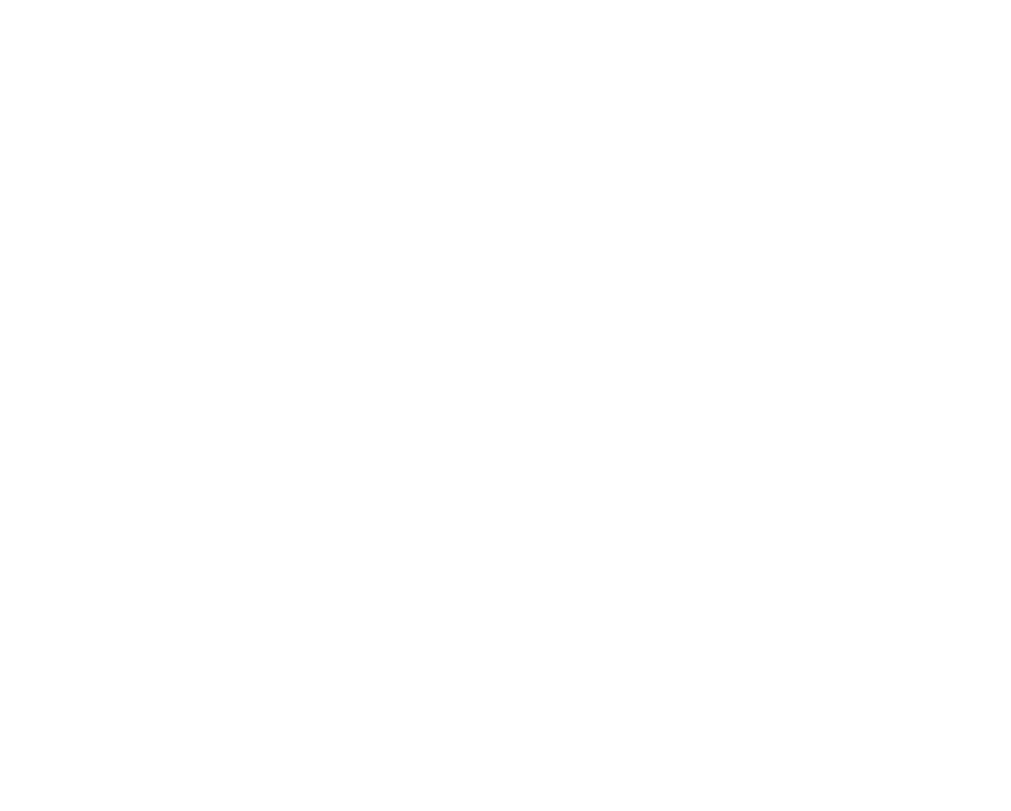

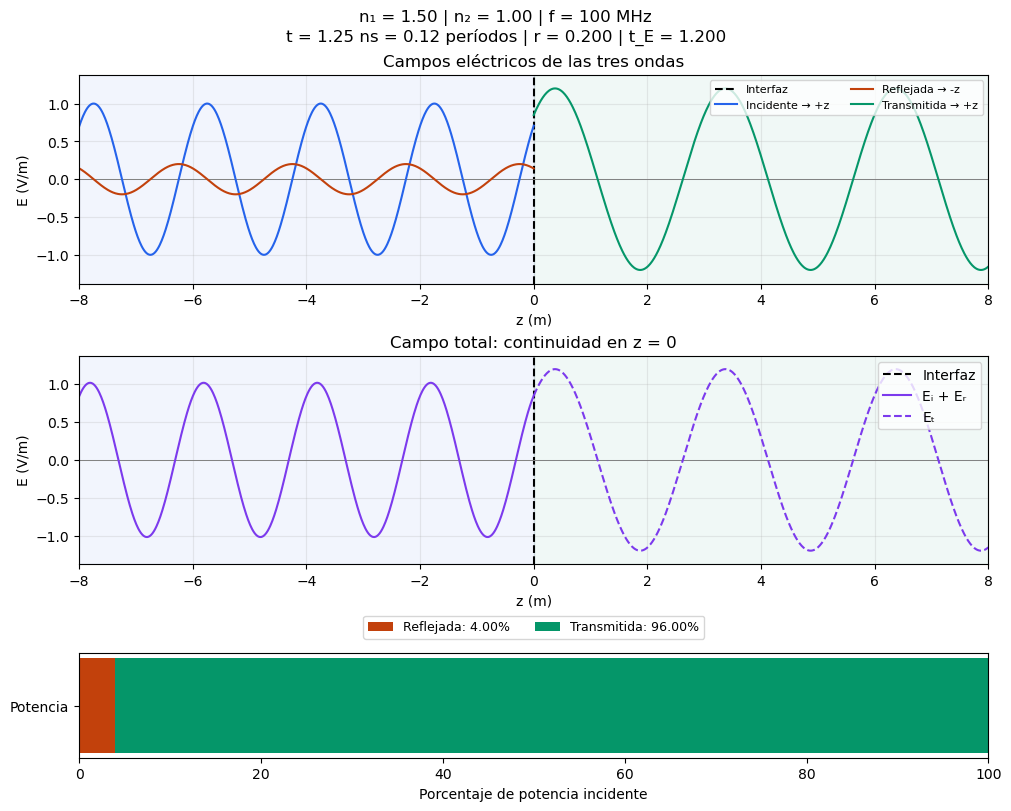

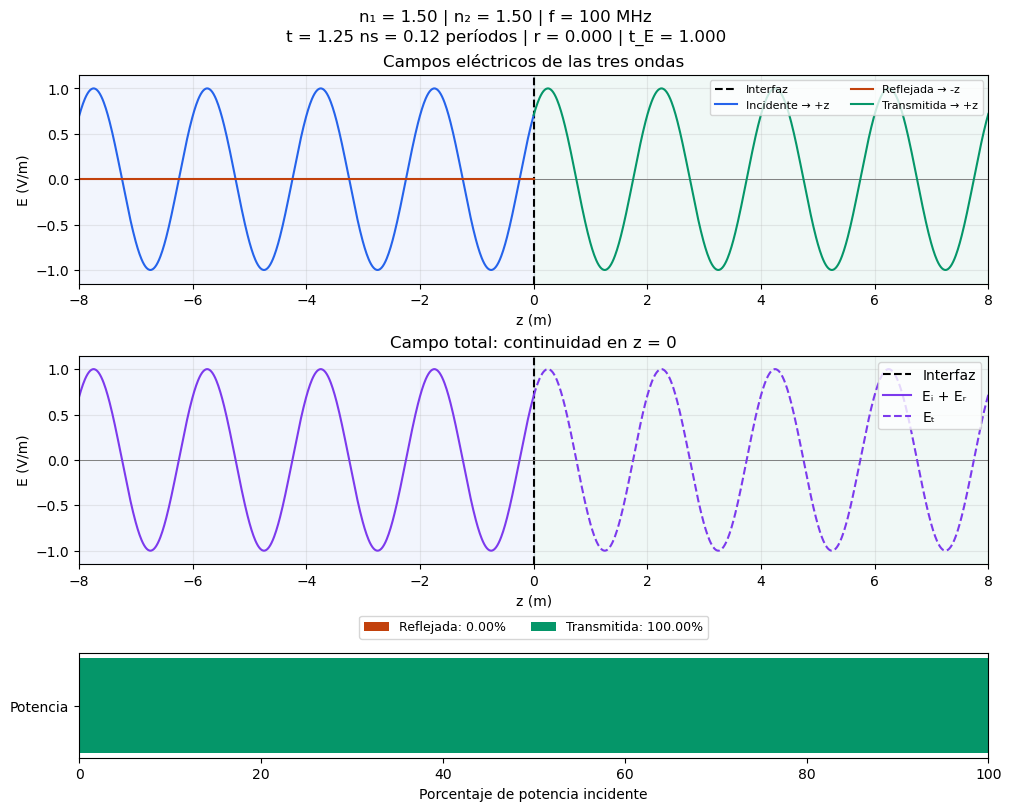

In [6]:
for n1, n2 in casos:
    fig = crear_figura(
        n1=n1,
        n2=n2,
        E0=1.0,
        f_MHz=100.0,
        tau=0.125
    )

    display(fig)
    plt.close(fig)

## Ampliación: reflexión y transmisión al variar el índice

Para estudiar cómo cambia la distribución de energía, se mantiene fijo
el índice n₁ y se varía el índice n₂.

Las fracciones de potencia son:

$$
R(n_2)=\left(\frac{n_1-n_2}{n_1+n_2}\right)^2,
$$

$$
T(n_2)=\frac{4n_1n_2}{(n_1+n_2)^2}.
$$

Cuando n₂ = n₁, las impedancias coinciden: R = 0 y T = 1.
Al alejarse de esta condición, aparece reflexión.

La gráfica muestra ambas curvas y señala los resultados correspondientes
al valor seleccionado de n₂.

Estas curvas se obtienen evaluando expresiones analíticas.
En el modelo utilizado no dependen de la frecuencia, porque los índices
son constantes y los medios no presentan absorción ni dispersión.

In [7]:
def crear_grafica_RT(n1=1.5, n2_actual=1.0):
    n2_valores = np.linspace(1.0, 3.0, 600)

    R_valores = (
        (n1 - n2_valores) / (n1 + n2_valores)
    )**2

    T_valores = (
        4 * n1 * n2_valores / (n1 + n2_valores)**2
    )

    _, _, R_actual, T_actual = coeficientes(n1, n2_actual)

    fig, ax = plt.subplots(
        figsize=(9, 4.5),
        layout="constrained"
    )

    ax.plot(
        n2_valores,
        100 * R_valores,
        color="#c2410c",
        label="Potencia reflejada R"
    )

    ax.plot(
        n2_valores,
        100 * T_valores,
        color="#059669",
        label="Potencia transmitida T"
    )

    ax.axvline(
        n1,
        color="black",
        linestyle="--",
        label="n₂ = n₁"
    )

    ax.scatter(
        [n2_actual], [100 * R_actual],
        color="#c2410c", s=65, zorder=3
    )

    ax.scatter(
        [n2_actual], [100 * T_actual],
        color="#059669", s=65, zorder=3
    )

    ax.set(
        xlim=(1, 3),
        ylim=(-3, 103),
        xlabel="Índice del segundo medio n₂",
        ylabel="Porcentaje de potencia incidente",
        title=(
            f"n₁ = {n1:.2f} | "
            f"Punto seleccionado: n₂ = {n2_actual:.2f}\n"
            f"R = {100 * R_actual:.2f}% | "
            f"T = {100 * T_actual:.2f}%"
        )
    )

    ax.grid(alpha=0.25)
    ax.legend(loc="center right")

    return fig


def mostrar_RT(n1, n2_actual):
    fig = crear_grafica_RT(n1, n2_actual)
    display(fig)
    plt.close(fig)


explorador_RT = widgets.interactive(
    mostrar_RT,
    n1=widgets.FloatSlider(
        value=1.5, min=1, max=3, step=0.05,
        description="n₁ fijo:",
        continuous_update=False
    ),
    n2_actual=widgets.FloatSlider(
        value=1.0, min=1, max=3, step=0.05,
        description="n₂ elegido:",
        continuous_update=False
    )
)

display(explorador_RT)

interactive(children=(FloatSlider(value=1.5, continuous_update=False, description='n₁ fijo:', max=3.0, min=1.0…

## Ampliación: visualización del campo magnético

Además del campo eléctrico, se representa el campo magnético H,
medido en A/m. Como ambos medios tienen permeabilidad μ₀:

$$
\mathbf{B}=\mu_0\mathbf{H}.
$$

Por tanto, B y H tienen la misma estructura espacial y temporal,
con un factor constante entre sus magnitudes.

Las componentes magnéticas de cada onda son:

$$
H_i=\frac{n_1}{Z_0}E_i,
$$

$$
H_r=-\frac{n_1}{Z_0}E_r,
$$

$$
H_t=\frac{n_2}{Z_0}E_t.
$$

El signo negativo de H_r garantiza que el vector de Poynting
de la onda reflejada apunte hacia -z:

$$
S_{r,z}=E_rH_r=-\frac{n_1}{Z_0}E_r^2.
$$

Los campos totales son:

$$
H_{\mathrm{total}}=
\begin{cases}
H_i+H_r, & z<0,\\
H_t, & z>0.
\end{cases}
$$

La visualización compara los campos individuales y totales de E y H.
Los campos totales tangenciales deben ser continuos en la interfaz.

Para facilitar la lectura, las gráficas magnéticas utilizan mA/m:

$$
1\ \mathrm{A/m}=1000\ \mathrm{mA/m}.
$$

In [8]:
def campos_magneticos(z, tiempo, n1, n2, E0=1.0, f=100e6):
    Ei, Er, Et = campos(z, tiempo, n1, n2, E0, f)

    Hi = n1 * Ei / Z0
    Hr = -n1 * Er / Z0
    Ht = n2 * Et / Z0

    return Hi, Hr, Ht


def crear_figura_magnetica(
    n1, n2, E0=1.0, f_MHz=100.0, tau=0.0
):
    f = f_MHz * 1e6
    tiempo = tau / f

    r, tE, _, _ = coeficientes(n1, n2)

    z1 = np.linspace(-8, 0, 700)
    z2 = np.linspace(0, 8, 700)

    Ei, Er, _ = campos(z1, tiempo, n1, n2, E0, f)
    _, _, Et = campos(z2, tiempo, n1, n2, E0, f)

    Hi, Hr, _ = campos_magneticos(
        z1, tiempo, n1, n2, E0, f
    )
    _, _, Ht = campos_magneticos(
        z2, tiempo, n1, n2, E0, f
    )

    # Conversión de A/m a mA/m.
    Hi, Hr, Ht = 1000 * Hi, 1000 * Hr, 1000 * Ht

    limite_E = 1.15 * E0 * max(1 + abs(r), tE)

    limite_H = (
        1.15 * 1000 * E0 / Z0
        * max(n1 * (1 + abs(r)), n2 * tE)
    )

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 7),
        layout="constrained"
    )

    for fila in range(2):
        for columna in range(2):
            ax = axes[fila, columna]

            ax.axvspan(
                -8, 0, color="#2563eb", alpha=0.06
            )
            ax.axvspan(
                0, 8, color="#059669", alpha=0.06
            )
            ax.axvline(
                0, color="black", linestyle="--"
            )
            ax.axhline(
                0, color="gray", linewidth=0.7
            )

            limite = limite_E if fila == 0 else limite_H

            ax.set(
                xlim=(-8, 8),
                ylim=(-limite, limite),
                xlabel="z (m)",
                ylabel="E (V/m)" if fila == 0 else "H (mA/m)"
            )

            ax.grid(alpha=0.25)

    for ax, curvas, nombre in [
        (axes[0, 0], (Ei, Er, Et), "E"),
        (axes[1, 0], (Hi, Hr, Ht), "H")
    ]:
        ax.plot(
            z1, curvas[0],
            color="#2563eb",
            label=nombre + " incidente"
        )
        ax.plot(
            z1, curvas[1],
            color="#c2410c",
            label=nombre + " reflejado"
        )
        ax.plot(
            z2, curvas[2],
            color="#059669",
            label=nombre + " transmitido"
        )

        ax.legend(loc="upper right", fontsize=8)

    axes[0, 1].plot(
        z1, Ei + Er,
        color="#7c3aed", label="Eᵢ + Eᵣ"
    )
    axes[0, 1].plot(
        z2, Et,
        color="#7c3aed",
        linestyle="--", label="Eₜ"
    )

    axes[1, 1].plot(
        z1, Hi + Hr,
        color="#7c3aed", label="Hᵢ + Hᵣ"
    )
    axes[1, 1].plot(
        z2, Ht,
        color="#7c3aed",
        linestyle="--", label="Hₜ"
    )

    for ax in axes[:, 1]:
        ax.legend(loc="upper right", fontsize=8)

    axes[0, 0].set_title("Campos eléctricos individuales")
    axes[0, 1].set_title("E total: continuidad en la interfaz")
    axes[1, 0].set_title("Campos magnéticos individuales")
    axes[1, 1].set_title("H total: continuidad en la interfaz")

    fig.suptitle(
        f"n₁ = {n1:.2f} | n₂ = {n2:.2f} | "
        f"f = {f_MHz:.0f} MHz\n"
        f"t = {tiempo * 1e9:.2f} ns = "
        f"{tau:.3f} períodos"
    )

    return fig

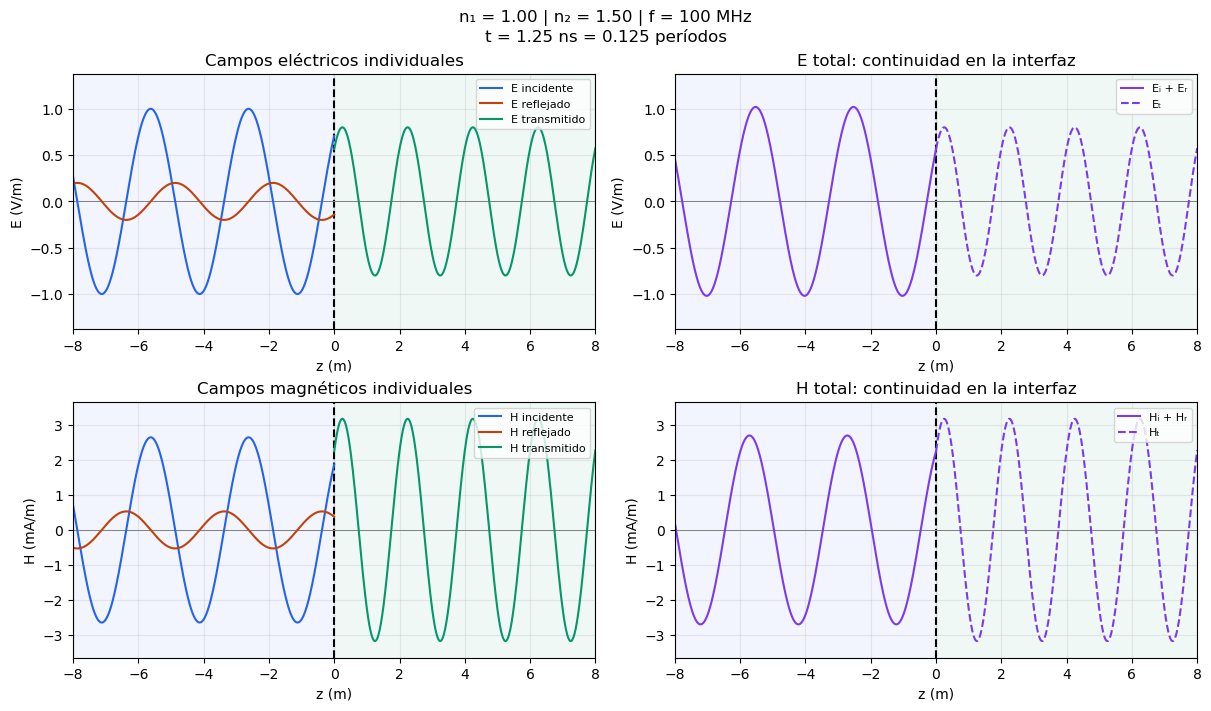

In [9]:
fig = crear_figura_magnetica(
    n1=1.0,
    n2=1.5,
    E0=1.0,
    f_MHz=100.0,
    tau=0.125
)

display(fig)
plt.close(fig)

### Exploración de los campos eléctrico y magnético

Utilice el reproductor para observar cómo evolucionan E y H.

Para n₂ > n₁, el campo eléctrico reflejado presenta inversión de fase.
Sin embargo, la relación entre H_r y E_r incluye un signo negativo
adicional debido a la dirección de propagación reflejada.

En la interfaz se deben cumplir simultáneamente:

$$
E_i+E_r=E_t,
\qquad
H_i+H_r=H_t.
$$

Observe que las curvas de los campos totales se conectan en z = 0
durante toda la evolución temporal.

Las escalas de E y H tienen unidades diferentes. Sus alturas en
las gráficas no deben compararse directamente como si fueran
magnitudes de la misma clase.

In [10]:
def mostrar_magnetico(n1, n2, E0, f_MHz, cuadro):
    tau = cuadro / 40
    f = f_MHz * 1e6
    tiempo = tau / f

    fig = crear_figura_magnetica(
        n1, n2, E0, f_MHz, tau
    )

    display(fig)
    plt.close(fig)

    E1, E2, H1, H2 = frontera(
        tiempo, n1, n2, E0, f
    )

    print("Continuidad en z = 0:")
    print(f"|E lado 1 - E lado 2| = {abs(E1 - E2):.3e} V/m")
    print(f"|H lado 1 - H lado 2| = {abs(H1 - H2):.3e} A/m")


n1_m = widgets.FloatSlider(
    value=1.0, min=1, max=3, step=0.05,
    description="n₁:", continuous_update=False
)

n2_m = widgets.FloatSlider(
    value=1.5, min=1, max=3, step=0.05,
    description="n₂:", continuous_update=False
)

E0_m = widgets.FloatSlider(
    value=1.0, min=0.2, max=5, step=0.1,
    description="E₀ (V/m):", continuous_update=False
)

f_m = widgets.FloatSlider(
    value=100, min=50, max=200, step=5,
    description="f (MHz):", continuous_update=False
)

cuadro_m = widgets.IntSlider(
    value=0, min=0, max=80, step=1,
    description="Cuadro:", continuous_update=False
)

play_m = widgets.Play(
    value=0, min=0, max=80, step=1,
    interval=350
)

enlace_m = widgets.jslink(
    (play_m, "value"),
    (cuadro_m, "value")
)

salida_m = widgets.interactive_output(
    mostrar_magnetico,
    {
        "n1": n1_m,
        "n2": n2_m,
        "E0": E0_m,
        "f_MHz": f_m,
        "cuadro": cuadro_m,
    }
)

panel_m = widgets.VBox([
    widgets.HBox([n1_m, n2_m]),
    widgets.HBox([E0_m, f_m]),
    widgets.HBox([play_m, cuadro_m]),
])

display(panel_m, salida_m)

Output()

## Resultados estáticos de las ampliaciones

Se guardan una gráfica de R y T y las distribuciones de E y H
para los tres casos de comparación.

Estas salidas permiten consultar los resultados en la vista
estática del notebook en GitHub.

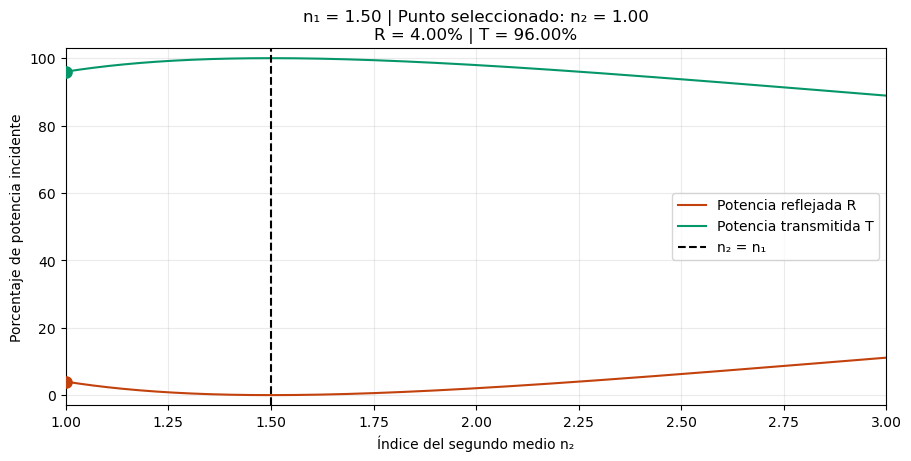

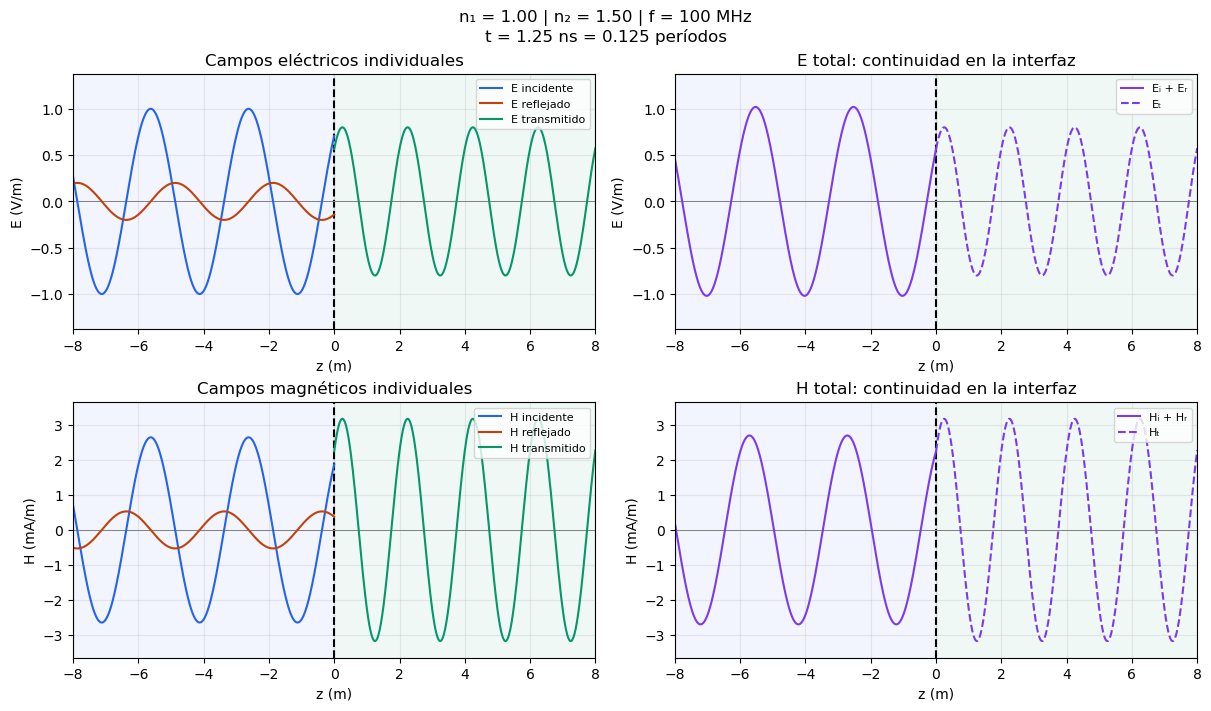

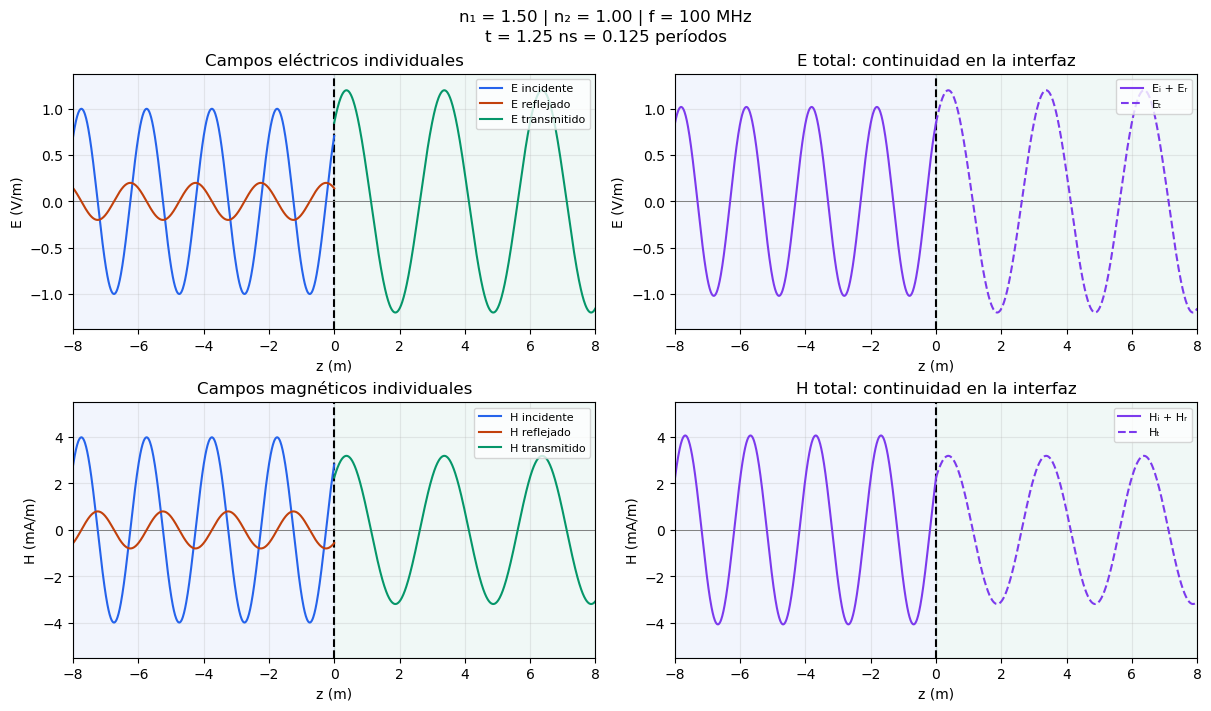

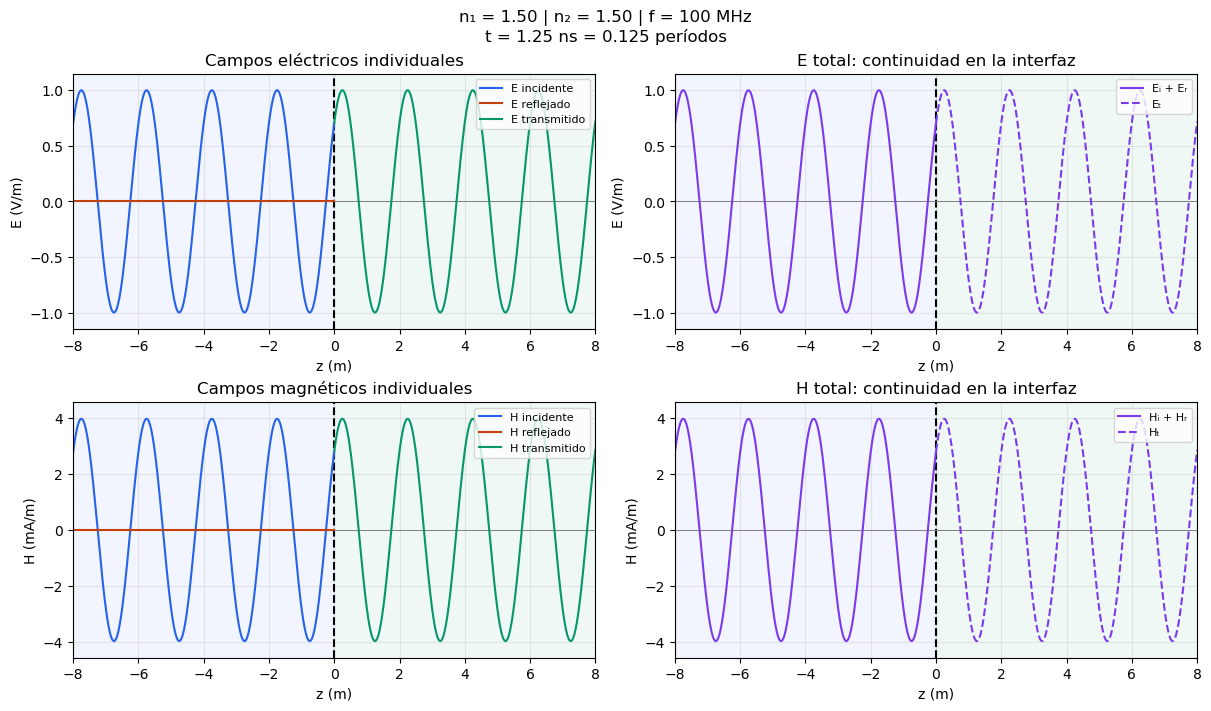

In [11]:
fig = crear_grafica_RT(n1=1.5, n2_actual=1.0)
display(fig)
plt.close(fig)

for n1, n2 in [
    (1.0, 1.5),
    (1.5, 1.0),
    (1.5, 1.5)
]:
    fig = crear_figura_magnetica(
        n1=n1,
        n2=n2,
        E0=1.0,
        f_MHz=100.0,
        tau=0.125
    )

    display(fig)
    plt.close(fig)